# PM2.5 multivariate regression and assumption checks
This analysis examines how PM2.5 levels relate to weather conditions, time of day, and characteristics of the surrounding area. A multiple regression model is used to explore these relationships while accounting for several variables at once. The analysis also checks the model’s assumptions and uses sensor-clustered standard errors to account for observations from the same sensor being related over time.

In [1]:
import pandas as pd, numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import scipy.stats as st

df = pd.read_parquet('master_hourly (2).parquet')
df = df[df['hours_since_obs'] == 0].copy()      # guardrail: real readings only
df['weekend'] = df['dow'] >= 5

cont = ['temp','rhum','wspd_ms','wind_u','prcp',
        'canopy_pct','impervious_pct','dist_downtown_m',
        'road_len_expwy_500','industrial_m2_500']

# aligned frame: drop NaN across EVERY column the formula uses, so rows line up for clustering
need = cont + ['pm25','hour','weekend','is_holiday','month','sensor_id']
dm = df.dropna(subset=need).copy()
dm['sensor_code'] = pd.factorize(dm['sensor_id'])[0]   # integer codes for cluster SEs
print("rows:", len(dm))
print("sensors:", dm.sensor_id.nunique())


rows: 88456
sensors: 20


## Data and setup
The model uses observed readings and complete cases for the outcome, predictors and sensor ID. Citywide pollution aggregates and lag variables are excluded, matching the NO₂ model. Put the parquet file alongside this notebook, or update the path below.

In [2]:
f = ('pm25 ~ temp+rhum+wspd_ms+wind_u+prcp'
     '+canopy_pct+impervious_pct+dist_downtown_m+road_len_expwy_500+industrial_m2_500'
     '+C(hour)+weekend+is_holiday+C(month)')
m = smf.ols(f, data=dm).fit()
resid, fitted = m.resid, m.fittedvalues
print('R2', round(m.rsquared, 3))
print(m.params.round(3))

R2 0.321
Intercept              7.847
C(hour)[T.1]          -0.111
C(hour)[T.2]          -0.105
C(hour)[T.3]          -0.032
C(hour)[T.4]          -0.045
C(hour)[T.5]           0.033
C(hour)[T.6]           0.197
C(hour)[T.7]           0.692
C(hour)[T.8]           0.882
C(hour)[T.9]           1.366
C(hour)[T.10]          1.318
C(hour)[T.11]          1.444
C(hour)[T.12]          1.343
C(hour)[T.13]          1.403
C(hour)[T.14]          1.117
C(hour)[T.15]          0.828
C(hour)[T.16]          0.769
C(hour)[T.17]          0.766
C(hour)[T.18]          0.960
C(hour)[T.19]          1.063
C(hour)[T.20]          0.997
C(hour)[T.21]          0.870
C(hour)[T.22]          0.414
C(hour)[T.23]          0.067
weekend[T.True]       -1.182
is_holiday[T.True]    -0.314
C(month)[T.2]          1.842
C(month)[T.3]         -2.530
C(month)[T.4]         -8.843
C(month)[T.5]         -8.057
C(month)[T.6]        -12.120
C(month)[T.7]         -9.973
C(month)[T.8]         -7.446
C(month)[T.9]         -6.556
C(mon

The R² and coefficients above are calculated for PM2.5. The units of each coefficient depend on the units of its predictor; see the standardized-predictor section for a comparison.

In [3]:
print("uncontrolled pm25~temp slope:", smf.ols('pm25 ~ temp', data=dm).fit().params['temp'].round(3))

uncontrolled pm25~temp slope: -0.006


Compare the unadjusted temperature slope with the adjusted temperature coefficient above. The difference can reflect the other variables in the model, but does not by itself establish a causal or seasonal explanation.

## Collinearity (VIF)

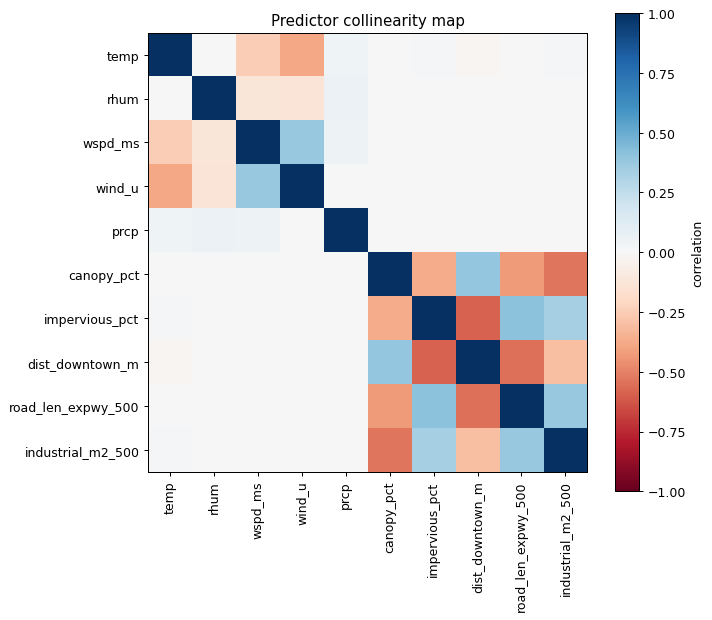

In [4]:
plt.figure(figsize=(8,7))
corr = dm[cont].corr()
plt.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)
plt.xticks(range(len(cont)), cont, rotation=90); plt.yticks(range(len(cont)), cont)
plt.colorbar(label='correlation'); plt.title('Predictor collinearity map'); plt.tight_layout(); plt.show()

In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
X = add_constant(dm[cont])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print(vif.round(2))

const                 1.00
temp                  1.20
rhum                  1.03
wspd_ms               1.20
wind_u                1.32
prcp                  1.01
canopy_pct            1.59
impervious_pct        1.62
dist_downtown_m       1.87
road_len_expwy_500    1.60
industrial_m2_500     1.49
dtype: float64


VIFs here cover continuous predictors only, as in the original notebook; they do not assess collinearity with the hour and month indicators.

## Assumption checks

### 1. Independence of errors

In [6]:
from statsmodels.stats.stattools import durbin_watson
print("Durbin-Watson:", round(durbin_watson(resid), 3))   # <<2 = positive autocorrelation

# remedy: cluster-robust SEs by sensor (fixes autocorrelation + heteroscedasticity for inference)
m_robust = smf.ols(f, data=dm).fit(cov_type='cluster', cov_kwds={'groups': dm['sensor_code'].values})
cmp = pd.DataFrame({'coef': m.params, 'se_ols': m.bse, 'se_clustered': m_robust.bse})
cmp['t_clustered'] = (cmp['coef']/cmp['se_clustered']).round(1)
print(cmp.loc[['wspd_ms','temp','canopy_pct','impervious_pct','dist_downtown_m'],
              ['coef','se_ols','se_clustered','t_clustered']].round(4))
print("Clustered coefficient table:")
print(pd.DataFrame({"coefficient": m_robust.params, "clustered_se": m_robust.bse, "p_value": m_robust.pvalues}).round(4).to_string())


Durbin-Watson: 0.269
                   coef  se_ols  se_clustered  t_clustered
wspd_ms         -0.7433  0.0089        0.0169        -44.1
temp             0.2245  0.0031        0.0073         30.6
canopy_pct      -0.0439  0.0037        0.0137         -3.2
impervious_pct  -0.0034  0.0012        0.0051         -0.7
dist_downtown_m -0.0000  0.0000        0.0000         -0.5
Clustered coefficient table:
                    coefficient  clustered_se  p_value
Intercept                7.8472        0.6422   0.0000
C(hour)[T.1]            -0.1106        0.0345   0.0013
C(hour)[T.2]            -0.1054        0.0370   0.0044
C(hour)[T.3]            -0.0316        0.0439   0.4716
C(hour)[T.4]            -0.0448        0.0335   0.1819
C(hour)[T.5]             0.0330        0.0494   0.5041
C(hour)[T.6]             0.1972        0.0914   0.0309
C(hour)[T.7]             0.6922        0.0897   0.0000
C(hour)[T.8]             0.8823        0.0799   0.0000
C(hour)[T.9]             1.3663        0.0730 

Clustered standard errors allow correlated errors within each sensor and unequal error variance. They do not change coefficients or fix the underlying dependence, and do not account for correlation across sensors. Interpret inference cautiously when the number of sensor clusters is small. The overall Durbin–Watson statistic depends on row order; the per-sensor check below is more informative.

### 2 & 3. Linearity + homoscedasticity (residuals vs fitted)

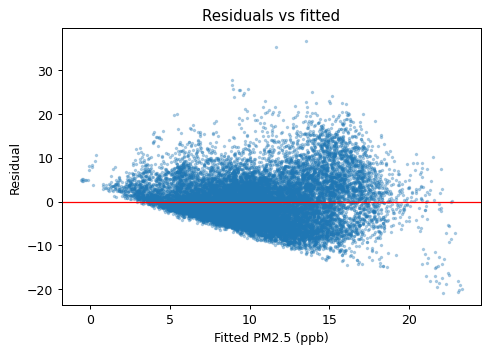

In [7]:
samp = np.random.default_rng(0).choice(len(resid), min(20000, len(resid)), replace=False)
plt.figure(figsize=(6,4))
plt.scatter(fitted.iloc[samp], resid.iloc[samp], s=3, alpha=0.3)
plt.axhline(0, color='red', lw=1)
plt.xlabel('Fitted PM2.5 (ppb)'); plt.ylabel('Residual'); plt.title('Residuals vs fitted'); plt.show()

Inspect the residual plot for curvature and changes in spread. Robust standard errors can address unequal variance in inference, but do not correct nonlinearity or outliers.

In [8]:
from statsmodels.stats.diagnostic import het_breuschpagan
bp = het_breuschpagan(resid, m.model.exog)
print("Breusch-Pagan p-value:", f"{bp[1]:.3g}")   # ~0 expected at this n; judge from the plot, clustered SEs handle it

Breusch-Pagan p-value: 4.25e-306


The Breusch–Pagan test examines unequal variance under its assumptions. Its p-value can be sensitive to large samples and dependence; interpret alongside the plot.

### 4. Normality of residuals

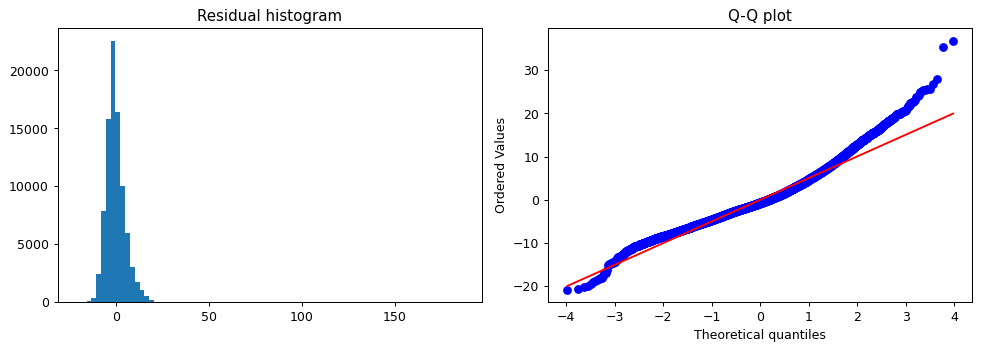

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(resid, bins=80); ax[0].set_title('Residual histogram')
st.probplot(resid.iloc[samp], dist='norm', plot=ax[1]); ax[1].set_title('Q-Q plot')
plt.tight_layout(); plt.show()

Residual normality is not required for unbiased OLS coefficients. Inspect the Q–Q plot and histogram for skewness and heavy tails; clustering and the number of sensors matter for inference.

sensors: 20
count    20.000
mean      0.866
std       0.047
min       0.691
25%       0.866
50%       0.881
75%       0.887
max       0.903
dtype: float64
share with autocorr > 0.3: 1.0


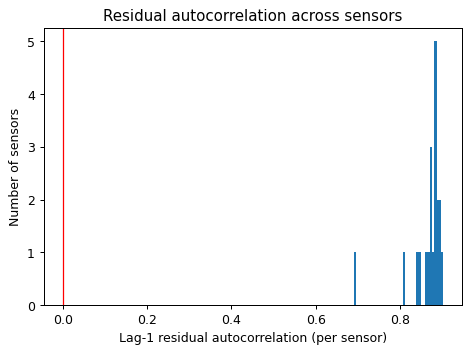

In [10]:
# Independence, per sensor: lag-1 residual autocorrelation within each sensor
tmp = dm[['sensor_id','ts_utc']].copy()
tmp['resid'] = m.resid.values                      # aligned to dm (model was fit on dm)

def lag1_acf(g):
    r = g.sort_values('ts_utc')['resid']
    return r.autocorr(lag=1) if len(r) >= 10 else np.nan

ac = tmp.groupby('sensor_id').apply(lag1_acf).dropna()
print("sensors:", len(ac))
print(ac.describe().round(3))
print("share with autocorr > 0.3:", round((ac > 0.3).mean(), 3))

plt.figure(figsize=(6,4))
plt.hist(ac, bins=40)
plt.xlabel('Lag-1 residual autocorrelation (per sensor)')
plt.ylabel('Number of sensors')
plt.title('Residual autocorrelation across sensors')
plt.axvline(0, color='red', lw=1)
plt.show()

The lag-1 calculation compares successive available observations within a sensor; a gap can exceed one hour. Values near 1 indicate strong positive residual persistence.

### 5. Influential outliers (Cook’s distance, on a sample of up to 5,000 rows)

In [11]:
s2 = dm.sample(min(5000, len(dm)), random_state=0)
cooks = smf.ols(f, data=s2).fit().get_influence().cooks_distance[0]
thr = 4/len(s2)
print(f"max Cook's D = {cooks.max():.4f}  | threshold 4/n = {thr:.6f}  | points over = {(cooks>thr).sum()}")

max Cook's D = 0.0100  | threshold 4/n = 0.000800  | points over = 240


Cook’s distance is computed on a reproducible sample, so this cannot rule out influential observations outside the sample. The 4/n threshold is a screening guide, not an automatic deletion rule.

## Standardized coefficients (comparable effect sizes)

In [12]:
dz = dm.copy()
for c in cont:
    dz[c] = (dz[c] - dz[c].mean()) / dz[c].std()
m2 = smf.ols(f, data=dz).fit()
print(m2.params[cont].round(3))

temp                  2.632
rhum                  1.944
wspd_ms              -1.695
wind_u               -0.063
prcp                 -0.021
canopy_pct           -0.258
impervious_pct       -0.061
dist_downtown_m      -0.054
road_len_expwy_500   -0.134
industrial_m2_500     0.117
dtype: float64


These coefficients show the change in PM2.5 for a one-standard-deviation increase in each continuous predictor, holding the others fixed. The outcome has not been standardized.

## Conclusions
- The same-hour model explains about 32.1% of variation in PM2.5 across 88,456 complete observations from 20 sensors.
- Holding the other predictors fixed, wind speed and canopy have negative coefficients, while temperature and humidity have positive coefficients. The strongest continuous predictors by one-standard-deviation change are temperature, humidity, and wind speed. These are associations, not proof of cause.
- Continuous-predictor VIFs are below 2. The median per-sensor residual autocorrelation is 0.881, indicating strong persistence. The unequal-variance test rejects equal variance. Sensor-clustered standard errors address within-sensor correlation for inference, but only 20 clusters and potential cross-sensor correlation limit certainty.
- The Cook’s distance screen flagged 240 of 5,000 sampled rows above 4/n; investigate sensitivity to these observations before drawing strong conclusions.
- This is a same-hour explanatory model, not a three-hour-ahead forecast.